In [37]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

My current portfolio exists of 600X, SPYL, EMIM and TEET (at Euronext Amsterdam). By using the Efficient Frontier, I would like to optimize the distribution of this portfolio.

In [78]:
symbols = ['600X.AS', 'CSPX.AS', 'EMIM.AS', 'TEET.AS'] # CSPX instead of SPYL, since earlier opening date with the same underlying index.
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")
raw_data = yf.download(symbols, start = '2020-10-01') # 600X.AS opened on 2020-10-01.

data = raw_data['Close']

600X.AS: State Street SPDR STOXX Europe 600 SRI UCITS ETF EUR Acc
CSPX.AS: iShares Core S&P 500 UCITS ETF USD (Acc)
EMIM.AS: iShares Core MSCI EM IMI UCITS ETF USD (Acc)
TEET.AS: VanEck European Equal Weight Screened UCITS ETF


[*********************100%***********************]  4 of 4 completed


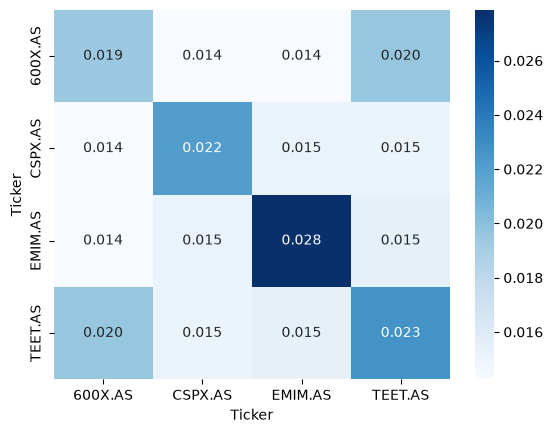

In [48]:
returns = data.pct_change().dropna()
cov_matrix = returns.cov() * 252 # Annualized
mean_returns = returns.mean() * 252 # # Annualized

sn.heatmap(cov_matrix, annot=True, fmt='.3f', cmap='Blues')
plt.show()

It is noteworthy that 600X and TEET have the highest covariance. This could be explained by noting that the TEET is a weighted variant of 600X.


All 4 stocks have a mean $\mu_i = E[R_i]$ and a weight $w_i$ (with $\sum_{i=1}^{4} w_i = 1$). With 600X, CSPX, EMIM and TEET $i = 1, 2, 3, 4$ respectively.
$$ \mu = \begin{bmatrix} \mu_1 \\ \mu_2 \\ \mu_3 \\ \mu_4 \end{bmatrix} \quad w = \begin{bmatrix} w_1 \\ w_2 \\ w_3 \\ w_4 \end{bmatrix} \quad \Sigma = \begin{bmatrix} \sigma_{11} & \sigma_{12} & \sigma_{13} & \sigma_{14} \\ \sigma_{21} & \sigma_{22} & \sigma_{23} & \sigma_{24} \\ \sigma_{31} & \sigma_{32} & \sigma_{33} & \sigma_{34} \\ \sigma_{41} & \sigma_{42} & \sigma_{43} & \sigma_{44} \end{bmatrix} $$
$$ \mu_p = w^\top \mu \qquad  \sigma_p^2 = w^\top \Sigma w$$

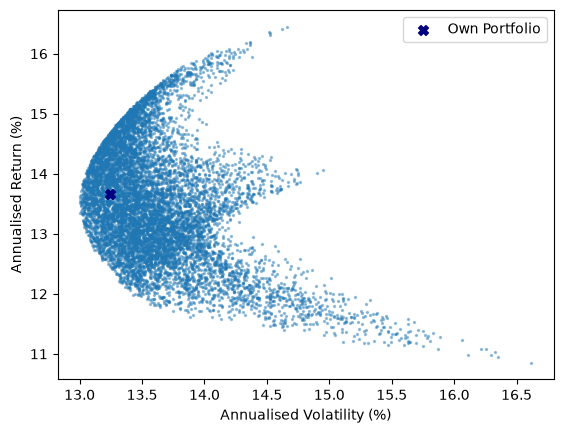

In [136]:
random_weights = np.random.dirichlet(np.ones(4), size=10000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = random_weights.T @ mean_returns
portfolio_variance = np.diag(random_weights.T @ cov_matrix @ random_weights) # Since the variance is the diagonal.
portfolio_volatility = np.sqrt(portfolio_variance)

own_weights = np.array([0.18, 0.29, 0.26, 0.27])
own_return = own_weights.T @ mean_returns
own_volatility = np.sqrt(own_weights.T @ cov_matrix @ own_weights)

plt.scatter(portfolio_volatility * 100, portfolio_returns * 100, s=2, alpha=0.4)
plt.scatter(own_volatility * 100, own_return * 100, s=50, c='navy', marker='X', label='Own Portfolio')
plt.legend()
plt.xlabel('Annualised Volatility (%)')
plt.ylabel('Annualised Return (%)')
plt.show()

A portfolio with minimum variance and maximum sharpe ratio can be found. Since $w_i \geq 0$ must hold, this cannot be solved with a formula.

$$ \min_{w} w^\top \Sigma w \qquad \max_{w} \frac{w^\top (\mu - r_f)}{\sqrt{w^\top \Sigma w}} \qquad w_i \geq 0 \ \wedge \ w^\top 1 = 1 $$

In [158]:
rf = 0.0225 # ECB rate

wmv = sp.optimize.minimize(lambda w: w.T @ cov_matrix @ w, x0 = np.ones(4) / 4, bounds=[(0, 1)] *4 , constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
wms = sp.optimize.minimize(lambda w: -w.T @ (mean_returns - rf) / (np.sqrt(w.T @ cov_matrix @ w)), x0 = np.ones(4) / 4, bounds=[(0, 1)] * 4, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1})

print(wmv.x)
print(wms.x)

[0.50964119 0.31442948 0.17592933 0.        ]
[0.         0.76424603 0.         0.23575397]
